# Charts from our results

Run **Analyze_Weather_Delays.ipynb** first. This notebook turns the tables in `results/` into charts and saves them there as PNG files.
Run it top to bottom. Each chart has a short note on how to read it.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Prepare_Data.ipynb").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the FlightDelaysAndWeather folder.")
RESULTS = ROOT / "results"
needed = ["data_inventory.csv", "rates_by_condition.csv", "rates_by_airport.csv",
          "cancellations_by_month_and_cause.csv", "bts_cause_vs_matched_weather.csv"]
missing = [name for name in needed if not (RESULTS / name).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run Analyze_Weather_Delays.ipynb first.")

AIRPORTS = ["BNA", "MEM", "TYS", "CHA"]
MIN_FLIGHTS = 50   # groups smaller than this are greyed out or left out
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.savefig(RESULTS / name, dpi=150, bbox_inches="tight")
    print("Saved", f"results/{name}")

## 1. Data overview
How many 2024 departures each airport has, and what share were cancelled. Use this as your first slide: it shows the size of the data.

Saved results/fig1_data_overview.png


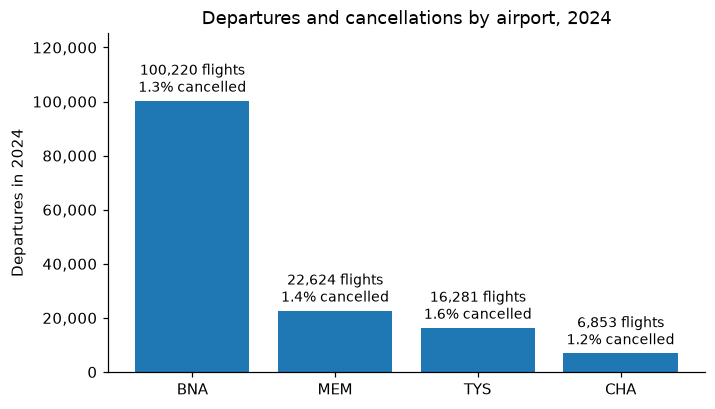

In [2]:
inv = pd.read_csv(RESULTS / "data_inventory.csv", index_col=0)
inv = inv.loc[[a for a in AIRPORTS if a in inv.index]]
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(inv.index, inv["flights"], color="tab:blue")
for bar, (_, row) in zip(bars, inv.iterrows()):
    label = f"{int(row['flights']):,} flights\n{100 * row['cancelled'] / row['flights']:.1f}% cancelled"
    ax.annotate(label, (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
ax.set_ylabel("Departures in 2024")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_ylim(0, inv["flights"].max() * 1.25)
ax.set_title("Departures and cancellations by airport, 2024")
save(fig, "fig1_data_overview.png")
plt.show()

## 2. How much worse than normal?
Each bar divides a condition's rate by the rate when no condition was reported. **1× means no difference** (the dashed line); 3× means three times as likely.
The black lines are approximate 95% intervals. Conditions with fewer than 50 flights are left out.

Saved results/fig2_times_more_likely.png


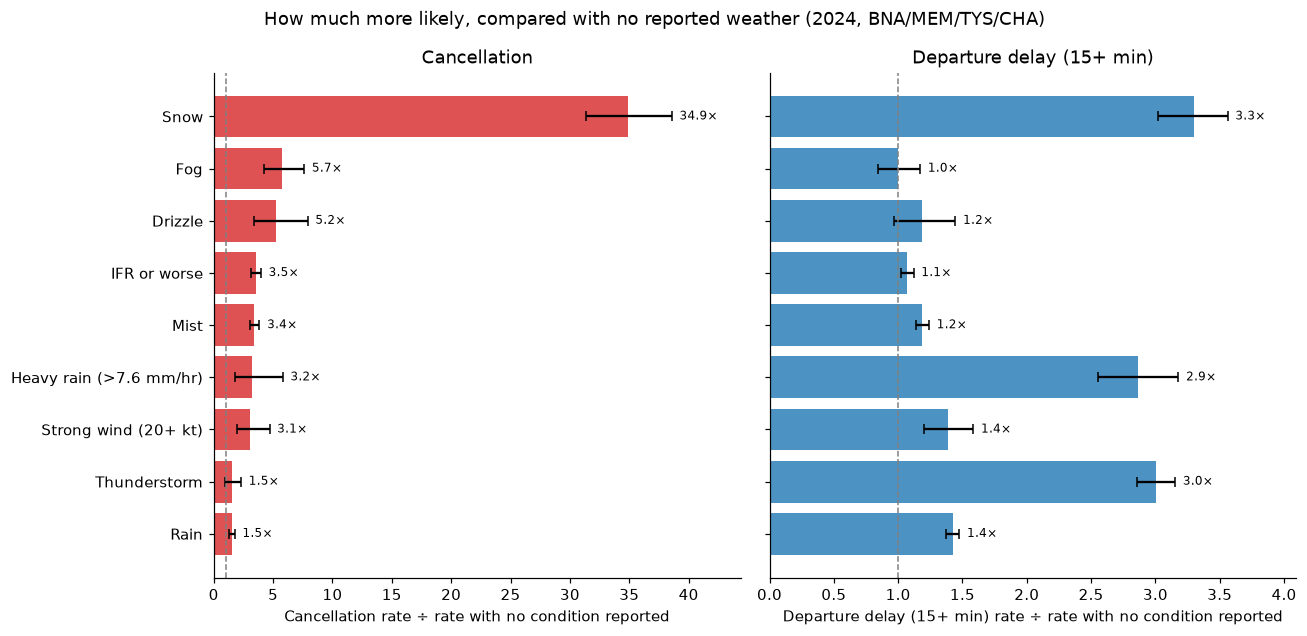

In [3]:
rates = pd.read_csv(RESULTS / "rates_by_condition.csv", index_col=0)
base = rates.loc["No condition reported"]
conds = rates.drop(index="No condition reported")
conds = conds[conds["flights"] >= MIN_FLIGHTS]

fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * len(conds) + 1.8), sharey=True)
panels = [("cancel_%", "cancel_low", "cancel_high", "Cancellation", "tab:red"),
          ("delay15_%", "delay_low", "delay_high", "Departure delay (15+ min)", "tab:blue")]
order = (conds["cancel_%"] / base["cancel_%"]).sort_values().index
for ax, (rate, low, high, title, color) in zip(axes, panels):
    ratio = conds.loc[order, rate] / base[rate]
    upper = conds.loc[order, high] / base[rate]
    err = [ratio - conds.loc[order, low] / base[rate], upper - ratio]
    ax.barh(order, ratio, xerr=err, color=color, alpha=0.8, capsize=3)
    ax.axvline(1, color="grey", linestyle="--", linewidth=1)
    for y, (value, end) in enumerate(zip(ratio, upper)):
        ax.annotate(f"{value:.1f}×", (max(value, end), y), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=8)
    ax.set_xlim(0, upper.max() * 1.15)
    ax.set_xlabel(f"{title} rate ÷ rate with no condition reported")
    ax.set_title(title)
fig.suptitle("How much more likely, compared with no reported weather (2024, BNA/MEM/TYS/CHA)")
fig.tight_layout()
save(fig, "fig2_times_more_likely.png")
plt.show()

## 3. Rates by airport and condition (heatmap)
Darker cells mean higher rates. Each cell shows the rate and the number of flights behind it.
**Grey cells have fewer than 50 flights**, so don't read much into them. A dash means no flights had that condition.

Saved results/fig3_airport_heatmap.png


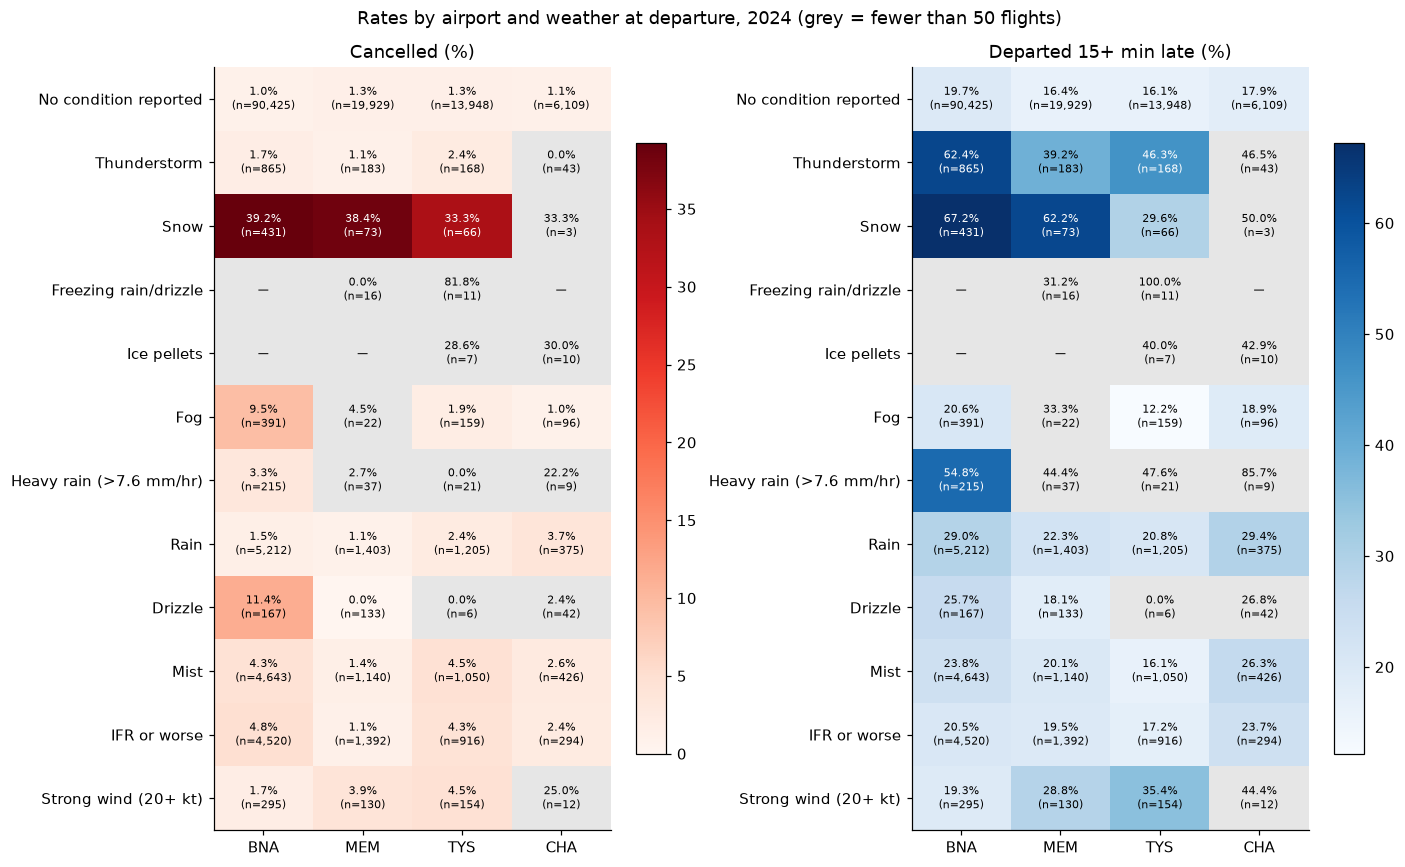

In [4]:
by_airport = pd.read_csv(RESULTS / "rates_by_airport.csv")
order = ["No condition reported"] + [c for c in rates.index if c != "No condition reported"]
counts = by_airport.pivot(index="condition", columns="airport", values="flights").reindex(order)
counts = counts[[a for a in AIRPORTS if a in counts.columns]]
keep = counts.index[counts.sum(axis=1) > 0]          # drop conditions never reported anywhere
counts = counts.loc[keep]

fig, axes = plt.subplots(1, 2, figsize=(13, 0.5 * len(keep) + 2))
for ax, (col, title, cmap) in zip(axes, [("cancel_%", "Cancelled (%)", "Reds"),
                                          ("delay15_%", "Departed 15+ min late (%)", "Blues")]):
    values = by_airport.pivot(index="condition", columns="airport", values=col).loc[keep, counts.columns]
    small = counts < MIN_FLIGHTS
    shown = np.ma.masked_array(values.to_numpy(dtype=float), mask=small.to_numpy())
    colormap = plt.get_cmap(cmap).copy()
    colormap.set_bad("#e6e6e6")
    image = ax.imshow(shown, cmap=colormap, aspect="auto")
    for i in range(len(keep)):
        for j in range(len(counts.columns)):
            n = int(counts.iat[i, j])
            text = "—" if n == 0 else f"{values.iat[i, j]:.1f}%\n(n={n:,})"
            dark = (not small.iat[i, j]) and values.iat[i, j] > 0.6 * np.nanmax(shown)
            ax.text(j, i, text, ha="center", va="center", fontsize=7.5, color="white" if dark else "black")
    ax.set_xticks(range(len(counts.columns)), counts.columns)
    ax.set_yticks(range(len(keep)), keep)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=0.8)
fig.suptitle("Rates by airport and weather at departure, 2024 (grey = fewer than 50 flights)")
fig.tight_layout()
save(fig, "fig3_airport_heatmap.png")
plt.show()

## 4. Cancellations by month and BTS cause
Each bar is one month, split by the cause airlines reported to BTS. Look for **weather** cancellations in winter storms and the
**carrier** spike in July, when the CrowdStrike IT outage grounded Delta flights. Summer **NAS** cancellations are often weather at other airports.

Saved results/fig4_cancellations_by_month.png


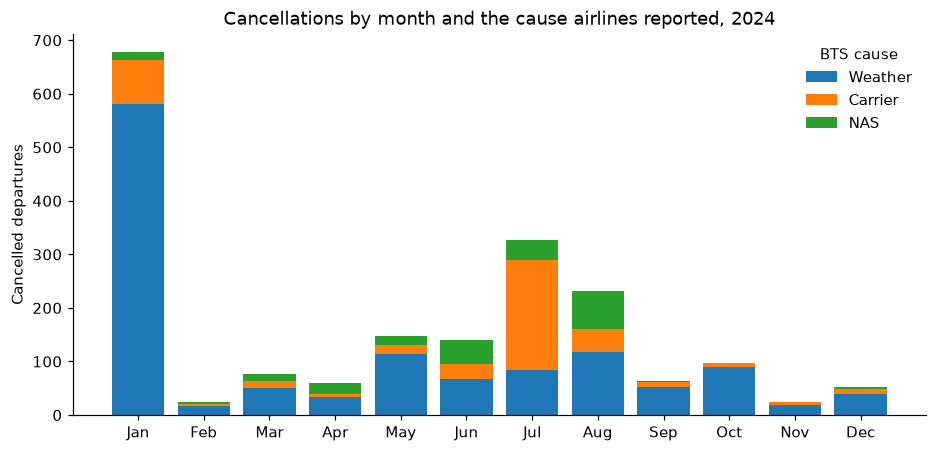

In [5]:
monthly = pd.read_csv(RESULTS / "cancellations_by_month_and_cause.csv", index_col=0)
monthly = monthly.drop(index="Total", errors="ignore").drop(columns="Total", errors="ignore")
monthly.index = pd.to_numeric(monthly.index).astype(int)
monthly = monthly.reindex(range(1, 13), fill_value=0)
colors = {"Weather": "tab:blue", "Carrier": "tab:orange", "NAS": "tab:green",
          "Security": "tab:purple", "Unknown": "tab:grey"}
causes = [c for c in colors if c in monthly.columns]

fig, ax = plt.subplots(figsize=(10, 4.5))
bottom = np.zeros(len(monthly))
for cause in causes:
    ax.bar(monthly.index, monthly[cause], bottom=bottom, label=cause, color=colors[cause])
    bottom += monthly[cause].to_numpy()
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Cancelled departures")
ax.set_title("Cancellations by month and the cause airlines reported, 2024")
ax.legend(title="BTS cause", frameon=False)
save(fig, "fig4_cancellations_by_month.png")
plt.show()

## 5. Do BTS causes match the weather we found?
For each cause airlines reported, the share of cancellations where we found a weather condition at the departure airport.
If many **weather** cancellations show no condition here, the weather was probably at the destination or a hub, or arrived after the matched report.
If **carrier** or **NAS** cancellations show weather, that's weather hidden under other codes.

Saved results/fig5_bts_cause_vs_weather.png


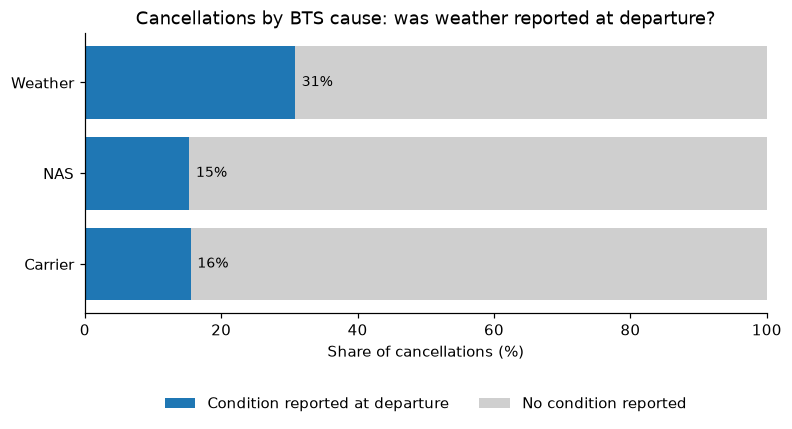

In [6]:
check = pd.read_csv(RESULTS / "bts_cause_vs_matched_weather.csv", index_col=0)
yes, no = "Condition reported at departure", "No condition reported"
for col in [yes, no]:
    if col not in check.columns:
        check[col] = 0.0
fig, ax = plt.subplots(figsize=(8, 0.6 * len(check) + 1.5))
ax.barh(check.index, check[yes], color="tab:blue", label=yes)
ax.barh(check.index, check[no], left=check[yes], color="#cfcfcf", label=no)
for y, value in enumerate(check[yes]):
    ax.text(value + 1, y, f"{value:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of cancellations (%)")
ax.set_title("Cancellations by BTS cause: was weather reported at departure?")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
save(fig, "fig5_bts_cause_vs_weather.png")
plt.show()

## 6. Case study: BNA on January 15, 2024
Hour by hour: scheduled departures, cancellations, and hours when the matched report showed snow (shaded).
This needs the combined CSV from Prepare_Data.ipynb.

Saved results/fig6_bna_jan15_case_study.png


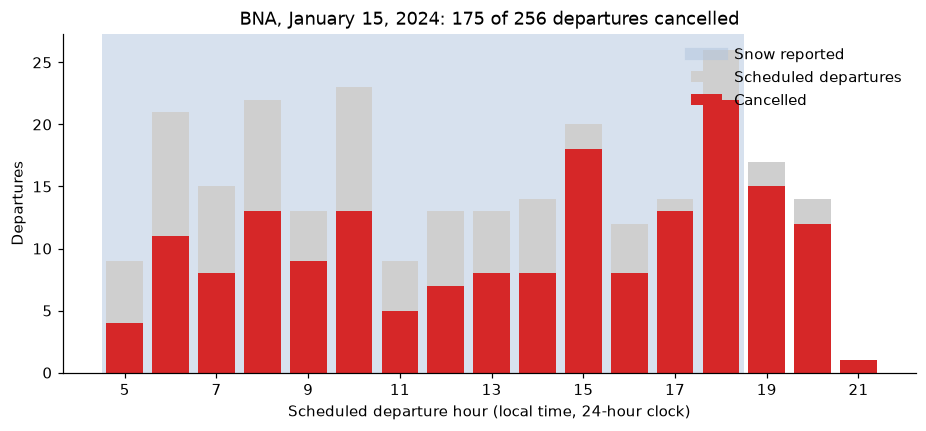

In [7]:
combined = ROOT / "data" / "processed" / "flights_weather_2024_full_year.csv"
if not combined.exists():
    print("Combined CSV not found. Run Prepare_Data.ipynb to make this chart.")
else:
    cols = ["Origin", "FlightDate", "CRSDepTime", "Cancelled", "snow_reported"]
    day = pd.read_csv(combined, usecols=cols)
    day = day[(day["Origin"] == "BNA") & (pd.to_datetime(day["FlightDate"]) == "2024-01-15")].copy()
    day["hour"] = pd.to_numeric(day["CRSDepTime"], errors="coerce") // 100
    hourly = day.groupby("hour").agg(flights=("Cancelled", "size"), cancelled=("Cancelled", "sum"),
                                     snow_share=("snow_reported", lambda s: s.eq(1).mean()))
    fig, ax = plt.subplots(figsize=(10, 4))
    for hour, share in hourly["snow_share"].items():
        if share >= 0.5:
            ax.axvspan(hour - 0.5, hour + 0.5, color="lightsteelblue", alpha=0.5, lw=0)
    ax.bar(hourly.index, hourly["flights"], color="#cfcfcf", label="Scheduled departures")
    ax.bar(hourly.index, hourly["cancelled"], color="tab:red", label="Cancelled")
    ax.plot([], [], color="lightsteelblue", lw=8, alpha=0.5, label="Snow reported")
    ax.set_xticks(range(int(hourly.index.min()), int(hourly.index.max()) + 1, 2))
    ax.set_xlabel("Scheduled departure hour (local time, 24-hour clock)")
    ax.set_ylabel("Departures")
    ax.set_title(f"BNA, January 15, 2024: {int(hourly['cancelled'].sum())} of {int(hourly['flights'].sum())} departures cancelled")
    ax.legend(frameon=False)
    save(fig, "fig6_bna_jan15_case_study.png")
    plt.show()

## Next
Commit the new PNGs with the notebook:

```
git add Make_Charts.ipynb results/
git commit -m "Add charts for results"
git push
```